In [2]:
import torch
import glob, json
from pathlib import Path
import pandas as pd

from botorch.utils import draw_sobol_samples
from botorch.sampling.pairwise_samplers import PairwiseSobolQMCNormalSampler

In [ ]:
import torch
from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_model
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition import UpperConfidenceBound
from botorch.optim import optimize_acqf
from botorch.utils import manual_seed
from botorch.acquisition.monte_carlo import qExpectedImprovement

with manual_seed(42):
    dim = 5
    q = 1
    bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])
    X = torch.rand(10, dim)
    Y = X[:, :1] * 100
    offset = -2
    gp = SingleTaskGP(X[:offset], Y[:offset])
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_model(mll)
    EI = qExpectedImprovement(model=gp, best_f=Y.max().item())
    next_X, acq_val = optimize_acqf(
        EI,
        bounds=torch.stack([torch.zeros(dim), torch.ones(dim)]),
        q=q,
        num_restarts=5,
        raw_samples=20,
    )
    print(next_X)

In [ ]:
import torch
from botorch.models import SingleTaskGP
from botorch.models.pairwise_gp import PairwiseGP, PairwiseLaplaceMarginalLogLikelihood
from botorch.acquisition.monte_carlo import qNoisyExpectedImprovement
from botorch.fit import fit_gpytorch_model
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.optim import optimize_acqf

def listwise_bo_estimation(X: torch.tensor, y: torch.tensor, dim: int, q=2, seed=42):
    # Infer ranking utility from data.
    rankGP  = PairwiseGP(X, y)
    mll = PairwiseLaplaceMarginalLogLikelihood(rankGP.likelihood, rankGP)
    fit_gpytorch_model(mll)
    y_utility = rankGP.utility.clone().detach().requires_grad_(True).reshape(-1, 1)
    print(y_utility)

    # Train model with ranking utility.
    bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])
    utilityGP = SingleTaskGP(X, y_utility)
    fit_gpytorch_model(ExactMarginalLogLikelihood(utilityGP.likelihood, utilityGP))
    qNEI = qNoisyExpectedImprovement(utilityGP, X)
    next_X, acq_val = optimize_acqf(
        qNEI,
        bounds=bounds,
        q=q,
        num_restarts=5,
        raw_samples=20,
    )
    return next_X, acq_val # this is not a paired candidates

nparam = 2
X = torch.rand(4, nparam)
y = torch.tensor([ # assume x[0] > x[1] > x[2] > x[3]
    [0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3],
])
listwise_bo_estimation(X, y, nparam, q=4)

In [1]:
from optimizers import pairwise_bo, mixed_bo
import numpy as np
from itertools import combinations
from botorch.acquisition.preference import AnalyticExpectedUtilityOfBestOption
import torch
from botorch.models import SingleTaskGP
from botorch.models.pairwise_gp import PairwiseGP, PairwiseLaplaceMarginalLogLikelihood
from botorch.acquisition.monte_carlo import qNoisyExpectedImprovement
from botorch.fit import fit_gpytorch_model
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.optim import optimize_acqf
import warnings
# suppress warnings from potential numerical issues
warnings.filterwarnings("ignore")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device: ', device)

# data generating helper functions
def utility(X):
    """ Given X, output corresponding utility (i.e., the latent function)
    """
    # y is weighted sum of X, with weight sqrt(i) imposed on dimension i
    weighted_X = X * torch.sqrt(torch.arange(X.size(-1), dtype=torch.float) + 1)
    y = torch.sum(weighted_X, dim=-1)
    return y


def generate_data(n, dim=2):
    """ Generate data X and y """
    # X is randomly sampled from dim-dimentional unit cube
    # we recommend using double as opposed to float tensor here for
    # better numerical stability
    X = torch.rand(n, dim, dtype=torch.float64)
    y = utility(X)
    return X, y

def generate_comparisons(y, n_comp, noise=0.1, replace=False):
    """  Create pairwise comparisons with noise """
    # generate all possible pairs of elements in y
    all_pairs = np.array(list(combinations(range(y.shape[0]), 2)))
    # randomly select n_comp pairs from all_pairs
    comp_pairs = all_pairs[np.random.choice(range(len(all_pairs)), n_comp, replace=replace)]
    # add gaussian noise to the latent y values
    c0 = y.to('cpu')[comp_pairs[:, 0]] + np.random.standard_normal(len(comp_pairs)) * noise
    c1 = y.to('cpu')[comp_pairs[:, 1]] + np.random.standard_normal(len(comp_pairs)) * noise
    reverse_comp = (c0 < c1).numpy()
    comp_pairs[reverse_comp, :] = np.flip(comp_pairs[reverse_comp, :], 1)
    comp_pairs = torch.tensor(comp_pairs).long()
    
    return comp_pairs

def make_new_data(X, next_X, comps, q_comp):
    """Given X and next_X,
    generate q_comp new comparisons between next_X
    and return the concatenated X and comparisons
    """
    # next_X is float by default; cast it to the dtype of X (i.e., double)
    next_X = next_X.to(X)
    next_y = utility(next_X)
    next_comps = generate_comparisons(next_y, n_comp=q_comp, noise=noise)
    comps = torch.cat([comps, next_comps + X.shape[-2]])
    X = torch.cat([X, next_X])
    return X, comps

def init_and_fit_model(X, comp, state_dict=None):
    """Model fitting helper function"""
    model = PairwiseGP(X, comp)
    mll = PairwiseLaplaceMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_model(mll)
    return mll, model


algos = ["EUBO", "rand", "listwise"]

NUM_TRIALS = 5 
NUM_BATCHES = 20 

dim = 4
NUM_RESTARTS = 3
RAW_SAMPLES = 256
q = 2  # number of points per query
q_comp = 1  # number of comparisons per query
noise = 0.1

# initial evals
best_vals = {}  # best observed values
for algo in algos:
    best_vals[algo] = []

# average over multiple trials
for i in range(NUM_TRIALS):
    torch.manual_seed(i)
    np.random.seed(i)
    data = {}
    models = {}

    # Create initial data
    init_X, init_y = generate_data(q, dim=dim)
    comparisons = generate_comparisons(init_y, q_comp, noise=noise)
    test_X, test_y = generate_data(1000, dim=dim)
    # X are within the unit cube
    bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])

    for algo in algos:
        best_vals[algo].append([])
        data[algo] = (init_X, comparisons)
        _, models[algo] = init_and_fit_model(init_X, comparisons)
        model = models[algo]

        best_next_y = utility(init_X).max().item()
        best_vals[algo][-1].append(best_next_y)

    # we make additional NUM_BATCHES comparison queries after the initial observation
    for j in range(1, NUM_BATCHES + 1):
        for algo in algos:
            if algo == "EUBO":
                # create the acquisition function object
                acq_func = AnalyticExpectedUtilityOfBestOption(pref_model=model)
                # optimize and get new observation
                next_X, acq_val = optimize_acqf(
                    acq_function=acq_func,
                    bounds=bounds,
                    q=q,
                    num_restarts=NUM_RESTARTS,
                    raw_samples=RAW_SAMPLES,
                )
            elif algo == "listwise":
                y_utility = models[algo].utility.clone().detach().requires_grad_(True).reshape(-1, 1)
                utilityGP = SingleTaskGP(data[algo][0], y_utility)
                fit_gpytorch_model(ExactMarginalLogLikelihood(
                    utilityGP.likelihood, utilityGP))
                qNEI = qNoisyExpectedImprovement(utilityGP, data[algo][0])
                next_X, acq_val = optimize_acqf(
                    qNEI,
                    bounds=bounds,
                    q=2,
                    num_restarts=5,
                    raw_samples=20,
                )
            else:
                # randomly sample data
                next_X, _ = generate_data(q, dim=dim)

            # update data
            X, comps = data[algo]
            X, comps = make_new_data(X, next_X, comps, q_comp)
            data[algo] = (X, comps)

            # refit models
            model = models[algo]
            _, model = init_and_fit_model(X, comps, model.state_dict())
            models[algo] = model

            # record the best observed values so far
            max_val = utility(X).max().item()
            best_vals[algo][-1].append(max_val)

device:  cuda


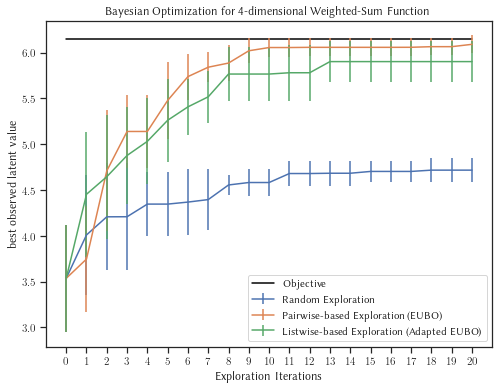

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
sns.set_theme(style='ticks')

plt.rcParams.update({"font.size": 14})

algo_labels = {
    "rand": "Random Exploration",
    "EUBO": "Pairwise-based Exploration (EUBO)",
    "listwise": "Listwise-based Exploration (Adapted EUBO)",
}


def ci(y):
    return 1.96 * y.std(axis=0) / np.sqrt(y.shape[0])


# the utility function is maximized at the full vector of 1
optimal_val = utility(torch.tensor([[1] * dim])).item()
iters = list(range(NUM_BATCHES + 1))

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
# plot the optimal value
ax.plot(iters, [optimal_val] * len(iters), label="Objective", color="black", linewidth=1.5)

# plot the the best observed value from each algorithm
for algo in ['rand', 'EUBO', 'listwise']:
    ys = np.vstack(best_vals[algo])
    ax.errorbar(iters, ys.mean(axis=0), yerr=ci(ys), label=algo_labels[algo], linewidth=1.5)

ax.set(
    xlabel=f"Exploration Iterations",
    ylabel="best observed latent value",
    title=f"Bayesian Optimization for {dim}-dimensional Weighted-Sum Function",
    xticks=iters,
)
ax.legend(loc="best")
plt.savefig("boperf.pdf")

In [ ]:
import os, glob, json
from pathlib import Path
import pandas as pd
import torch

def load_listwise_notie(domain, user_id, session_id):
    # load tasks
    tasks = glob.glob(
        f'../data/{domain}-listwise-notie/tasks/*.json')
    tasks_info = {}
    for task in tasks:
        obj = json.load(open(task))
        tasks_info[Path(task).stem] = obj['ground_truth']

    # load feedbacks, parameters, and options.
    files = glob.glob(
        f'../data/{domain}-listwise-notie/{user_id}-{session_id}/feedbacks/*.json')
    df = pd.DataFrame(columns=[
        'userID',
        'studyID',
        'sessionID',
        'taskID',
        'feedbackID',
        'iteration',
        'completeIteration',
        'incompleteIteration',
        'rating',
        'skip',
        'timePresent',
        'timeLastRating',
        'timeSubmit',
        'comment'
    ])
    for feedback_file in files:
        param_folder = feedback_file.replace(
            'feedbacks', 'parameters').removesuffix('.json')
        param_files = [param for param in glob.glob(f'{param_folder}/*.json')]
        options_file = [param_file.replace('parameters', 'options').replace(
            '.json', '.txt') for param_file in param_files]
        feedback = json.load(open(feedback_file))
        feedback['parameters'] = [
            json.load(open(param)) for param in param_files]
        feedback['option'] = [open(option_file).read()
                              for option_file in options_file]
        feedback['ground_truth'] = tasks_info[feedback['taskID']]
        df = pd.concat([df, pd.DataFrame([feedback])], ignore_index=True)
    df.sort_values(by='timePresent', inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df

def load_listwise_notie_data(domain, user_id, session_id, task_id):
    df = load_listwise_notie(domain, user_id, session_id)
    df = df[df['taskID'] == task_id]

    X, y = [], []
    k = 0
    for idx, row in df.iterrows():
        # infer ranking orders
        ranking = [-1, -1, -1, -1]
        for op in row.rating:
            if op['rating'] == '1st Choice':
                ranking[0] = op['id']
            elif op['rating'] == '2nd Choice':
                ranking[1] = op['id']
            elif op['rating'] == '3rd Choice':
                ranking[2] = op['id']
            elif op['rating'] == '4th Choice':
                ranking[3] = op['id']
            else: # I don't know, incomplete preference, we don't use these data for training
                pass

        comparisons = []
        if ranking[0] != -1 and ranking[1] != -1:
            comparisons.append([ranking[0]+k, ranking[1]+k])
        if ranking[0] != -1 and ranking[2] != -1:
            comparisons.append([ranking[0]+k, ranking[2]+k])
        if ranking[0] != -1 and ranking[3] != -1:
            comparisons.append([ranking[0]+k, ranking[3]+k])
        if ranking[1] != -1 and ranking[2] != -1:
            comparisons.append([ranking[1]+k, ranking[2]+k])
        if ranking[1] != -1 and ranking[3] != -1:
            comparisons.append([ranking[1]+k, ranking[3]+k])
        if ranking[2] != -1 and ranking[3] != -1:
            comparisons.append([ranking[2]+k, ranking[3]+k])

        params = []
        for param in row.parameters:
            params.append([
                param['reduction_ratio'],
                param['top_p'],
                param['temperature'],
                # param['repetition_penalty'],
                param['length_penalty'],
            ])
        print(ranking)
        print(params)

        X += params
        y += comparisons

        k += 4

    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)



X, y = load_listwise_notie_data('text', 'changkun', 'testsession', '1')
(X, y, X.shape, y.max().item())

In [ ]:
import glob
import json
import numpy as np
import pandas as pd
from pathlib import Path
import torch
def load_listwise_ranking(domain, user_id, session_id):
    # load tasks
    tasks = glob.glob(
        f'../data/{domain}-listwise-ranking/tasks/*.json')
    tasks_info = {}
    for task in tasks:
        obj = json.load(open(task))
        tasks_info[Path(task).stem] = obj['ground_truth']

    # load feedbacks, parameters, and options.
    files = glob.glob(
        f'../data/{domain}-listwise-ranking/{user_id}-{session_id}/feedbacks/*.json')
    df = pd.DataFrame(columns=[
        'userID',
        'studyID',
        'sessionID',
        'taskID',
        'feedbackID',
        'iteration',
        'completeIteration',
        'incompleteIteration',
        'rating',
        'skip',
        'timePresent',
        'timeLastRating',
        'timeSubmit',
        'comment'
    ])
    for feedback_file in files:
        param_folder = feedback_file.replace(
            'feedbacks', 'parameters').removesuffix('.json')
        param_files = [param for param in glob.glob(f'{param_folder}/*.json')]
        options_file = [param_file.replace('parameters', 'options').replace(
            '.json', '.txt') for param_file in param_files]
        feedback = json.load(open(feedback_file))
        feedback['parameters'] = [
            json.load(open(param)) for param in param_files]
        feedback['option'] = [open(option_file).read()
                              for option_file in options_file]
        feedback['ground_truth'] = tasks_info[feedback['taskID']]
        df = pd.concat([df, pd.DataFrame([feedback])], ignore_index=True)
    df.sort_values(by='timePresent', inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df


def load_listwise_ranking_data(domain, user_id, session_id, task_id):
    df = load_listwise_ranking(domain, user_id, session_id)
    df = df[df['taskID'] == task_id]

    X, y = [], []
    k = 0
    for idx, row in df.iterrows():
        print(row.rating)
        # infer rating position
        rating = ['', '', '', '']
        for op in row.rating:
            rating[op['id']] = op['rating']
        rating_map = {
            'Excellent': 5,
            'Good': 4,
            'Fair': 3,
            'Poor': 2,
            'Terrible': 1,
            "I don't know": -1,
        }

        # convert rating to pairwise comparisons.
        # TODO: sadly we don't know how to utilize the ranking distance.
        ranking = [rating_map[r] for r in rating]
        comparisons = []
        if ranking[0] != -1 and ranking[1] != -1:
            comparisons.append([0+k, 1+k])
        if ranking[0] != -1 and ranking[2] != -1:
            comparisons.append([0+k, 2+k])
        if ranking[0] != -1 and ranking[3] != -1:
            comparisons.append([0+k, 3+k])
        if ranking[1] != -1 and ranking[2] != -1:
            comparisons.append([1+k, 2+k])
        if ranking[1] != -1 and ranking[3] != -1:
            comparisons.append([1+k, 3+k])
        if ranking[2] != -1 and ranking[3] != -1:
            comparisons.append([2+k, 3+k])

        print('comparisons: ', comparisons)
        params = []
        for param in row.parameters:
            params.append([
                param['reduction_ratio'],
                param['top_p'],
                param['temperature'],
                # param['repetition_penalty'],
                param['length_penalty'],
            ])
        print(ranking)
        print(params)

        X += params
        y += comparisons

        k += 4

    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

X, y = load_listwise_ranking_data('text', 'changkun', 'testsession', '2')
(X, y, X.shape, y.max().item())

In [10]:
def load_pointwise(domain, user_id, session_id):
    # load tasks
    tasks = glob.glob(
        f'../data/text-pointwise/tasks/*.json')

    tasks_info = {}
    for task in tasks:
        obj = json.load(open(task))
        tasks_info[Path(task).stem] = obj['ground_truth']

    # load feedbacks, parameters, and options.
    files = glob.glob(
        f'../data/{domain}-pointwise/{user_id}-{session_id}/feedbacks/*.json')
    df = pd.DataFrame(columns=[
        'userID',
        'studyID',
        'sessionID',
        'taskID',
        'feedbackID',
        'groundTruth',
        'iteration',
        'completeIteration',
        'incompleteIteration',
        'rating',
        'skip',
        'timePresent',
        'timeLastRating',
        'timeSubmit',
        'comment'
    ])
    for feedback_file in files:
        param_folder = feedback_file.replace(
            'feedbacks', 'parameters').removesuffix('.json')
        param_file = [param for param in glob.glob(
            f'{param_folder}/*.json')][0]
        option_file = param_file.replace(
            'parameters', 'options').replace('.json', '.txt')
        feedback = json.load(open(feedback_file))
        param = json.load(open(param_file))
        option = open(option_file).read()
        feedback.update(param)
        feedback['option'] = option
        feedback['ground_truth'] = tasks_info[feedback['taskID']]
        df = pd.concat([df, pd.DataFrame([feedback])], ignore_index=True)
    df.sort_values(by='timePresent', inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df


def load_pointwise_data(domain: str, user_id: str, session_id: str, task_id: str):
    df = load_pointwise(domain, user_id, session_id)
    df = df[df['taskID'] == task_id].reset_index(drop=True)
    X, y = [], []
    for _, row in df.iterrows():
        if row.skip or row.groundTruth[0] == True:
            continue
        X.append([
            row['reduction_ratio'],
            row['top_p'],
            row['temperature'],
            # row['repetition_penalty'],
            row['length_penalty'],
        ])
        y = np.append(y, [row['rating']])
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

import numpy as np
load_pointwise_data('text', 'changkun', 'testsession', '3')

(tensor([[0.3991613686, 0.5109770298, 0.3220283687, 0.5257955194, 0.4753276110],
         [0.1809512079, 0.3614518940, 0.5728367567, 0.1443199068, 0.2209845036],
         [0.7153421044, 0.7692981362, 0.0721988827, 0.7859998345, 0.7753524184],
         [0.5537370443, 0.4064620435, 0.4712336957, 0.9232426882, 0.8855409026]]),
 tensor([[70.],
         [65.],
         [40.],
         [68.]]))